# Current milk model: evidence for PP1

Component 1 (PFOI), Farm X, herd level only. Compares the current structural model (`milk_baseline_adaptive`, pfoi-1.1) with persistence and linear regression on identical periods.

**Source.** Aggregate tables from rolling-origin runs the user executed (development block, origins 2019-2023). No animal-level data.
**Reading.** Accuracy = 100 - WAPE. Bias > 0 = over-forecast. Skill = 1 - MAE(current) / MAE(persistence). Cells with n < 12 are indicative.

## 1. Setup and palette check

In [5]:
# pip install matplotlib jupyterlab ipykernel

Defaulting to user installation because normal site-packages is not writeable
  Using cached jupyterlab-4.6.4-py3-none-any.whl.metadata (16 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jupyter_builder-1.2.3-py3-none-any.whl.metadata (7.8 kB)
  Using cached jupyter_lsp-2.3.1-py3-none-any.whl.metadata (1.8 kB)
  Using cached jupyter_server-2.21.1-py3-none-any.whl.metadata (8.5 kB)
  Using cached jupyterlab_server-2.28.1-py3-none-any.whl.metadata (5.8 kB)
  Using cached notebook_shim-0.2.4-py3-none-any.whl.metadata (4.0 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached certifi-2026.10.19-py3-none-any.whl.metadata (2.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached idna-3.20-py3-none-any.whl.metad

In [10]:
# pip install pandas

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 3.7 MB/s  0:00:03m0:00:010:01

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: /usr/local/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import subprocess, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs" / "data").exists() or (p / "components").exists())
DOCS = ROOT / "docs" if (ROOT / "docs" / "data").exists() else ROOT / "components" / "predictive_farm_intelligence" / "docs"

STYLE = {"current": ("Current model", "#2a78d6", "o"),
         "persistence": ("Persistence", "#eb6834", "s"),
         "linear": ("Linear regression", "#6250d6", "^")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
r = subprocess.run([sys.executable, str(DOCS / "tools" / "validate_palette.py"),
                    ",".join(c for _, c, _ in STYLE.values()), "--mode", "light"], capture_output=True, text=True)
print(r.stdout.splitlines()[-4] if r.returncode == 0 else r.stdout)
assert r.returncode == 0, "palette failed validation"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110})

## 2. Data

`linear_baseline_wape.csv` holds WAPE and bias per grain, horizon and target year, copied from the evaluated `matched` tables. `recovery_weekly_h4_E5a.csv` holds weekly 4-week accuracy after a break.

In [2]:
TARGET = {"monthly": {1: 92, 3: 90, 6: 88, 12: 85}, "weekly": {1: 93, 4: 90, 13: 87}, "daily": {1: 95, 7: 92, 14: 90}}
GRAINS = ["daily", "weekly", "monthly"]
d = pd.read_csv(DOCS / "data" / "linear_baseline_wape.csv")
rec = pd.read_csv(DOCS / "data" / "recovery_weekly_h4_E5a.csv")
for m in ("linear", "persistence", "current", "ridge"):
    d[f"{m}_acc"] = 100 - d[f"{m}_wape_pct"]
d["skill_vs_pers"] = 1 - d.current_wape_pct / d.persistence_wape_pct
d["gap_lin"] = d.current_acc - d.linear_acc
d["gap_pers"] = d.current_acc - d.persistence_acc
d["target"] = pd.to_numeric([TARGET[g].get(h) for g, h in zip(d.grain, d.horizon)])
d["indicative"] = d.n < 12
print(f"{len(d)} cells, {d.indicative.sum()} indicative (n < 12)")

51 cells, 16 indicative (n < 12)


## 3. Comparison table

Accuracy % for each model, current-model bias and skill against persistence. Change `GRAIN` to switch between daily, weekly and monthly.

In [3]:
GRAIN = "weekly"
t = d[d.grain == GRAIN].sort_values(["horizon", "target_year"])
show = t[["horizon", "target_year", "n", "linear_acc", "ridge_acc", "persistence_acc", "current_acc",
          "current_bias_pct", "skill_vs_pers", "target"]].round(1)
show["n"] = show.n.astype(int).astype(str) + np.where(t.indicative, " *", "")
display(show.rename(columns={"target_year": "year", "linear_acc": "linear", "ridge_acc": "ridge",
                             "persistence_acc": "persistence", "current_acc": "CURRENT",
                             "current_bias_pct": "bias %", "skill_vs_pers": "skill"}).reset_index(drop=True))

,horizon,year,n,linear,ridge,persistence,CURRENT,bias %,skill,target
0,1,2019,52,97.4,88.7,98.4,98.3,-0.2,-0.1,93.0
1,1,2020,50,97.4,88.7,97.9,97.6,0.5,-0.1,93.0
2,1,2021,50,97.3,87.0,97.8,97.8,0.1,-0.0,93.0
3,1,2022,27,91.1,39.5,94.3,94.3,1.5,-0.0,93.0
4,1,2023,26,90.7,87.9,90.8,90.0,2.8,-0.1,93.0
5,4,2019,49,93.0,87.7,96.9,96.8,-0.8,-0.0,90.0
6,4,2020,50,93.7,87.3,95.5,94.4,1.6,-0.2,90.0
7,4,2021,50,91.2,82.7,95.8,96.9,0.5,0.3,90.0
8,4,2022,28,82.8,21.7,87.6,91.5,5.9,0.3,90.0
9,4,2023,20,79.3,82.4,81.1,70.5,8.5,-0.6,90.0


## 4. Accuracy by horizon

How accuracy decays with horizon, per year. The current model separates from the others from about four weeks, and in 2021-2022 when the herd changed. Values below 0 % are drawn at 0 and labelled.

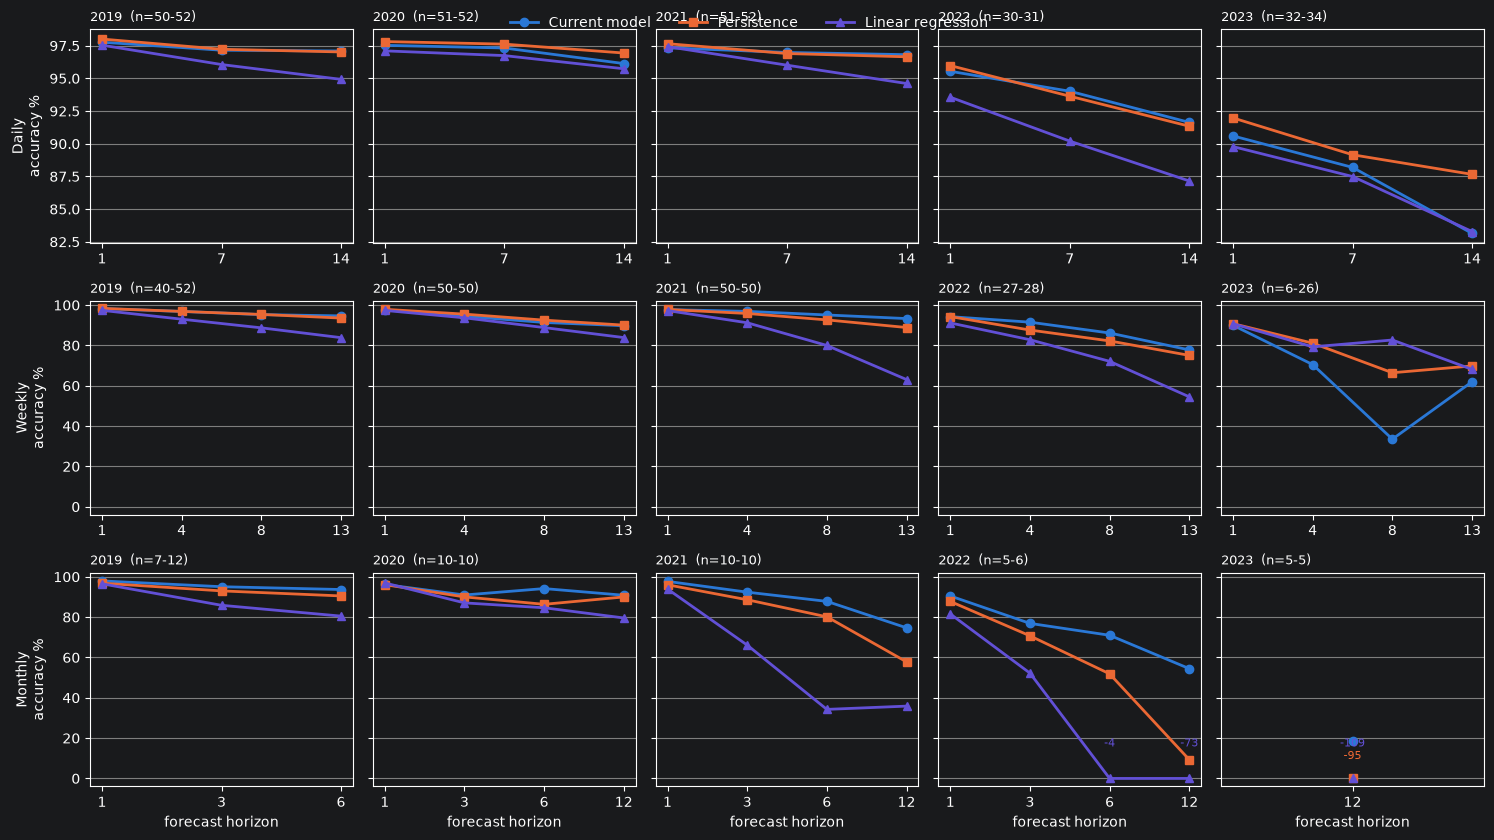

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8.5), sharey="row")
for r_, g in enumerate(GRAINS):
    for c, y in enumerate(range(2019, 2024)):
        ax = axes[r_, c]; s = d[(d.grain == g) & (d.target_year == y)].sort_values("horizon")
        ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
        for mi, (m, (lab, col, mk)) in enumerate(STYLE.items()):
            v = s[f"{m}_acc"] if g == "daily" else s[f"{m}_acc"].clip(lower=0)
            ax.plot(range(len(s)), v, color=col, marker=mk, ms=6, lw=2, label=lab)
            for x_, raw in zip(range(len(s)), s[f"{m}_acc"]):
                if g != "daily" and raw < 0:
                    ax.annotate(f"{raw:.0f}", (x_, 0), textcoords="offset points", xytext=(0, 5 + 9 * mi), ha="center", fontsize=8, color=col)
        ax.set_xticks(range(len(s))); ax.set_xticklabels(s.horizon.astype(str))
        if g != "daily": ax.set_ylim(-4, 102)
        ax.set_title(f"{y}  (n={int(s.n.min())}-{int(s.n.max())})" if len(s) else f"{y}", fontsize=9.5, loc="left")
        if c == 0: ax.set_ylabel(f"{g.title()}\naccuracy %")
        if r_ == 2: ax.set_xlabel("forecast horizon")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(.5, .99))
fig.tight_layout(); plt.show()

## 5. Where the current model wins and loses

Accuracy points of the current model minus a reference. Blue = current better. Colour is capped at +/-20 points; the printed number is the true gap. `*` = n < 12.

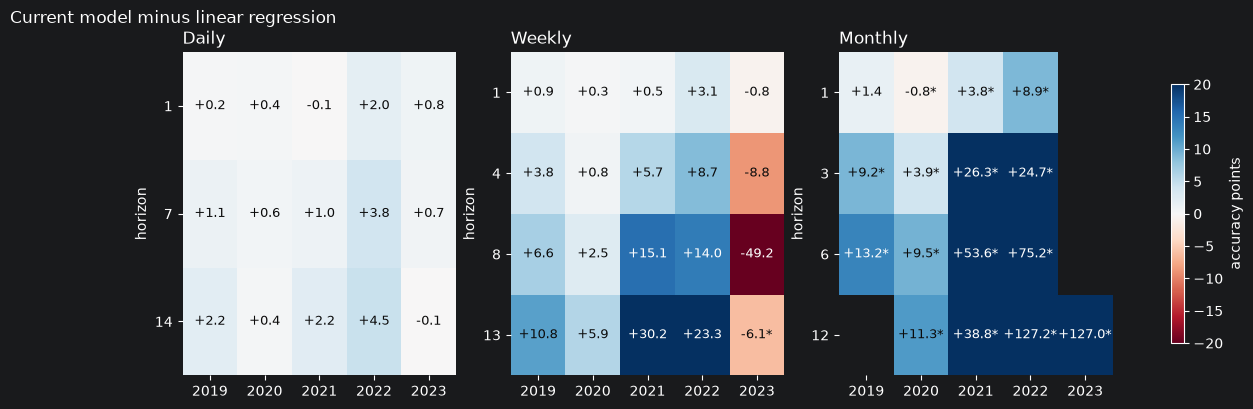

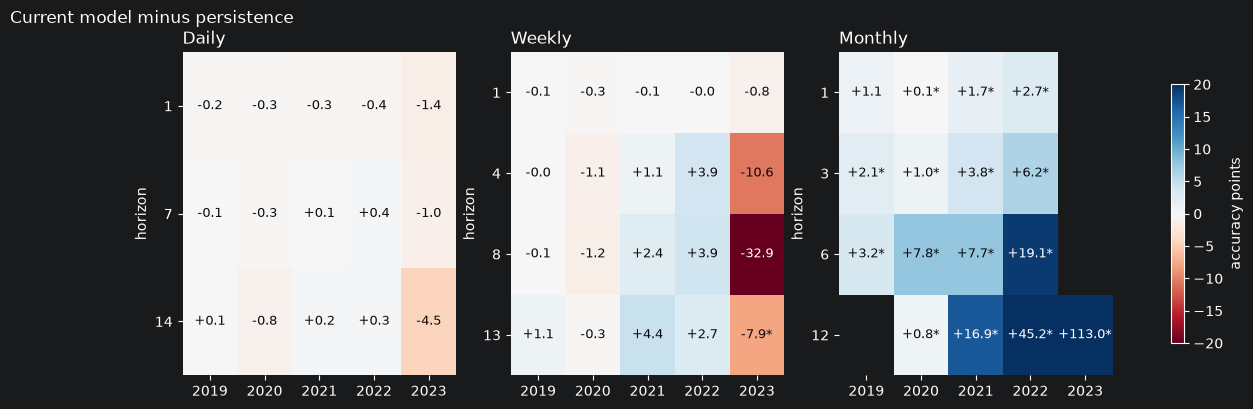

In [5]:
def heat(ref, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2)); lim = 20
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    for ax, g in zip(axes, GRAINS):
        p = d[d.grain == g].pivot(index="horizon", columns="target_year", values=f"gap_{ref}").reindex(columns=range(2019, 2024))
        n = d[d.grain == g].pivot(index="horizon", columns="target_year", values="n").reindex(columns=range(2019, 2024))
        im = ax.imshow(p.values, cmap="RdBu", norm=norm, aspect="auto")
        ax.set_xticks(range(5)); ax.set_xticklabels(range(2019, 2024)); ax.set_yticks(range(len(p))); ax.set_yticklabels(p.index)
        ax.set_title(g.title(), loc="left"); ax.set_ylabel("horizon")
        for i in range(p.shape[0]):
            for j in range(p.shape[1]):
                v = p.values[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:+.1f}" + ("*" if n.values[i, j] < 12 else ""), ha="center", va="center", fontsize=9,
                            color="white" if abs(v) > lim * .6 else INK)
        for sp in ax.spines.values(): sp.set_visible(False)
    fig.colorbar(im, ax=axes, shrink=.8, label="accuracy points"); fig.suptitle(title, x=.01, ha="left"); plt.show()

heat("lin", "Current model minus linear regression")
heat("pers", "Current model minus persistence")

## 6. Bias when the herd changed

Bias in 2021 and 2022. Linear drifts upward fastest; the current model is lower but not inside the agreed monthly +/-3 % band (shaded).

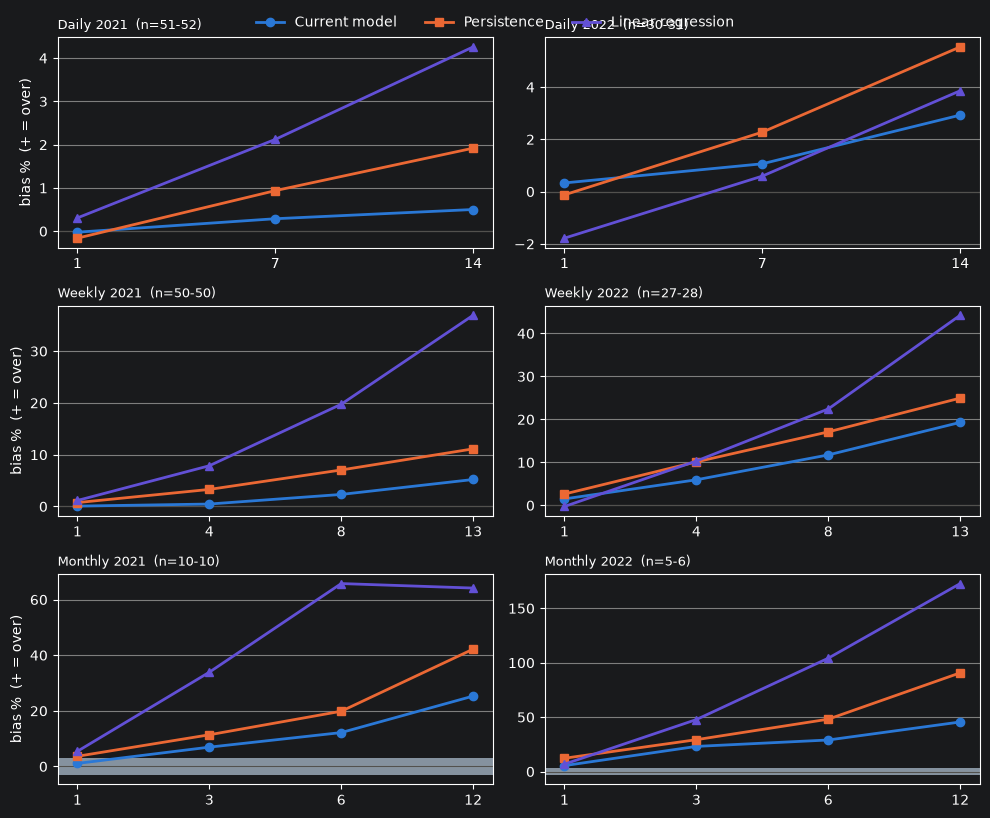

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(10, 8.2))
for r_, g in enumerate(GRAINS):
    for c, y in enumerate((2021, 2022)):
        ax = axes[r_, c]; s = d[(d.grain == g) & (d.target_year == y)].sort_values("horizon")
        ax.grid(axis="y", color=GRID, lw=.8); ax.axhline(0, color=MUTED, lw=.8)
        if g == "monthly": ax.axhspan(-3, 3, color="#cfe3f7", alpha=.6, lw=0)
        for m, (lab, col, mk) in STYLE.items():
            ax.plot(range(len(s)), s[f"{m}_bias_pct"], color=col, marker=mk, ms=6, lw=2, label=lab)
        ax.set_xticks(range(len(s))); ax.set_xticklabels(s.horizon.astype(str))
        ax.set_title(f"{g.title()} {y}  (n={int(s.n.min())}-{int(s.n.max())})", loc="left", fontsize=9.5)
        if c == 0: ax.set_ylabel("bias %  (+ = over)")
h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(.5, 1.0))
fig.tight_layout(); plt.show()

## 7. Recovery after a break

Weekly milk, 4 weeks ahead, after the 2022 milk gap (break E5a). Each model on its own periods. The agreed target is 90 % at 0-2 months; the current model does not reach it and is below persistence there.

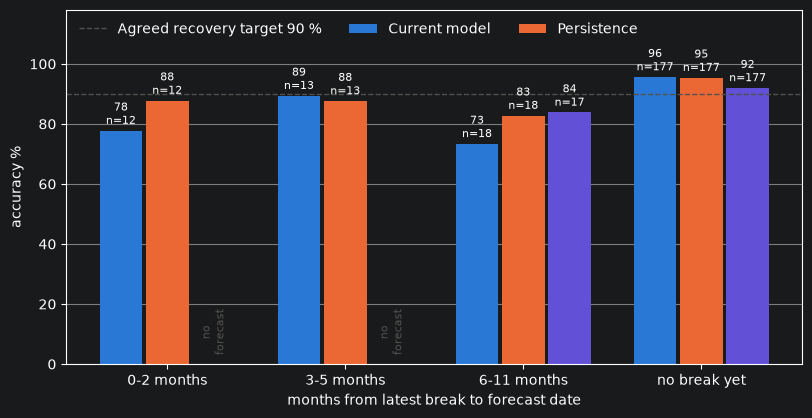

In [7]:
bands = ["0-2 months", "3-5 months", "6-11 months", "no break yet"]
fig, ax = plt.subplots(figsize=(9.5, 4.6)); ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True); w = .26
for i, (m, (lab, col, mk)) in enumerate(STYLE.items()):
    for j, b in enumerate(bands):
        row = rec[(rec.model == m) & (rec.since_break == b)]; x = j + (i - 1) * w
        if len(row):
            acc = 100 - float(row.wape_pct.iloc[0])
            ax.bar(x, acc, w * .92, color=col, label=lab if j == 0 else None)
            ax.text(x, acc + 1, f"{acc:.0f}\nn={int(row.n.iloc[0])}", ha="center", va="bottom", fontsize=8)
        else:
            ax.text(x, 3, "no\nforecast", ha="center", va="bottom", fontsize=8, color=MUTED, rotation=90)
ax.axhline(90, color=MUTED, ls="--", lw=1, label="Agreed recovery target 90 %")
ax.set_xticks(range(len(bands))); ax.set_xticklabels(bands); ax.set_ylim(0, 118)
ax.set_xlabel("months from latest break to forecast date"); ax.set_ylabel("accuracy %"); ax.legend(frameon=False, ncol=4, loc="upper left")
plt.show()

## 8. Accuracy against the agreed targets

Targets were frozen before measuring (`targets.md`). Dashed = target; hollow dot = n < 12. Persistence meets the accuracy targets almost as often as the current model, so skill and bias carry the argument.

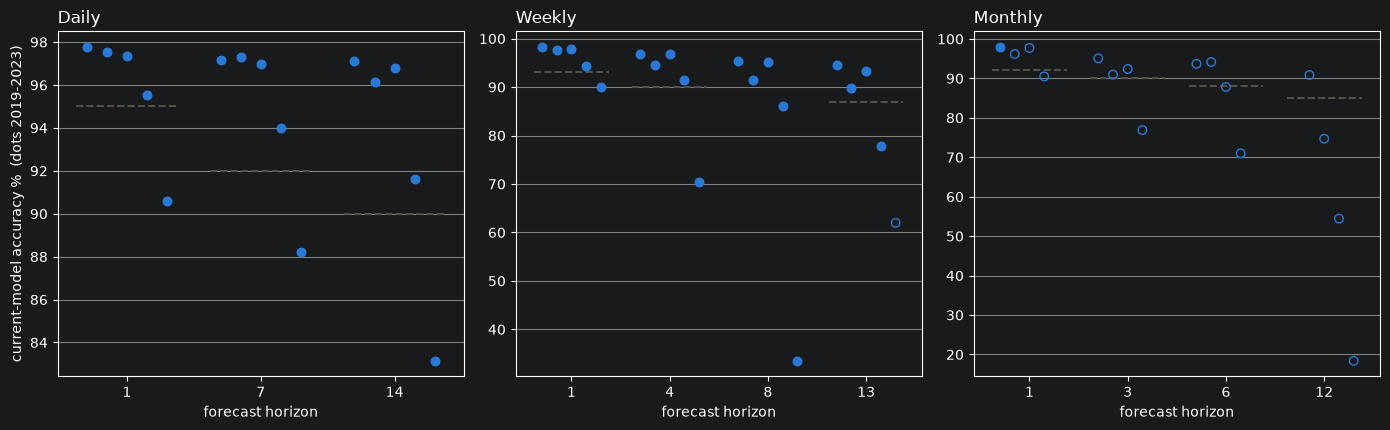

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, g in zip(axes, GRAINS):
    s = d[d.grain == g]; hs = sorted(s.horizon.unique()); ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
    for xi, hz in enumerate(hs):
        t_ = TARGET[g].get(hz)
        if t_ is not None: ax.hlines(t_, xi - .38, xi + .38, color=MUTED, ls="--", lw=1.4)
        for y in range(2019, 2024):
            row = s[(s.horizon == hz) & (s.target_year == y)]
            if len(row):
                big = int(row.n.iloc[0]) >= 12
                ax.scatter(xi + (y - 2021) * .15, max(float(row.current_acc.iloc[0]), 0), color=STYLE["current"][1], s=38,
                           facecolors=STYLE["current"][1] if big else "none", edgecolors=STYLE["current"][1], zorder=3)
    ax.set_xticks(range(len(hs))); ax.set_xticklabels(hs); ax.set_xlabel("forecast horizon"); ax.set_title(g.title(), loc="left")
axes[0].set_ylabel("current-model accuracy %  (dots 2019-2023)")
plt.tight_layout(); plt.show()

## 9. Claim checks

Each statement used on the slides, computed from the data. A claim that fails is reported, not dropped.

In [9]:
dt = d[d.target.notna()]
mon = d[d.grain == "monthly"]; wk = d[(d.grain == "weekly") & (d.horizon >= 4)]
sh = d[((d.grain == "daily") & d.horizon.isin([1, 7])) | ((d.grain == "weekly") & (d.horizon == 1))]
checks = pd.DataFrame([
    ("Current >= linear", f"{(d.gap_lin >= 0).sum()} of {len(d)} cells", "supported"),
    ("Current > persistence, monthly", f"{(mon.gap_pers > 0).sum()} of {len(mon)} cells (all n <= 12)", "supported, indicative"),
    ("Current >= persistence, weekly 4+ wk", f"{(wk.gap_pers >= 0).sum()} of {len(wk)} cells", "mixed"),
    ("Persistence ahead at 1 day to 1 week", f"{(sh.gap_pers < 0).sum()} of {len(sh)} cells", "limit: value claim starts ~4 weeks"),
    ("Monthly |bias| <= 3 %", f"{(mon.current_bias_pct.abs() <= 3).sum()} of {len(mon)} cells", "not supported"),
    ("Meets accuracy target (n >= 12)", f"{int(dt[dt.n >= 12].eval('current_acc >= target').sum())} of {(dt.n >= 12).sum()} cells", "reported"),
    ("Recovery 0-2 months >= 90 %", f"{100 - rec[(rec.model=='current') & (rec.since_break=='0-2 months')].wape_pct.iloc[0]:.1f} %", "not met"),
], columns=["Claim", "Result", "Status"])
display(checks)

,Claim,Result,Status
0,Current >= linear,44 of 51 cells,supported
1,"Current > persistence, monthly",16 of 16 cells (all n <= 12),"supported, indicative"
2,"Current >= persistence, weekly 4+ wk",7 of 15 cells,mixed
3,Persistence ahead at 1 day to 1 week,13 of 15 cells,limit: value claim starts ~4 weeks
4,Monthly |bias| <= 3 %,5 of 16 cells,not supported
5,Meets accuracy target (n >= 12),24 of 30 cells,reported
6,Recovery 0-2 months >= 90 %,77.8 %,not met


## 10. Limits

- **Short range.** Persistence is as good or better at 1 day to 1 week; the value claim starts at about 4 weeks.
- **2023 weekly weakness.** The current model is below persistence at 4-13 weeks; cause not yet diagnosed.
- **Recovery.** After a break the current model does not beat persistence and misses the 90 % target.
- **Bias.** Monthly bias is outside +/-3 % in most cells.
- **Evidence status.** Development block only. 2024-2026 is post-hoc and the monthly post-hoc run is pending. Boosted, TCN and residual-TCN are not yet evaluated.
- **Not in this notebook.** ETS, SARIMA and seasonal naive on identical periods, and real-data interval coverage.

## 11. Open items (commands the user runs; aggregate output only)

| Gap | Command |
|---|---|
| Skill against the best benchmark | `python -m components.predictive_farm_intelligence.pfoi.cli scorecard --block development --preset pfoi-1.1 --k anchor_first` |
| Interval calibration | same, with `--intervals aci` |
| 2024-2026 post-hoc | the post-hoc command in `docs/linear_baseline.md` |
| Boosted and TCN | `forecast_experiments --models boosted tcn tcn_residual` (see `docs/pp1_evidence_pack.md`, section e) |
| 2023 weekly cause | `pfoi.error_diagnostics` with the adaptive tag (see `docs/pp1_evidence_pack.md`, section e) |